# L6-2 用 tsid 串联：路径图与诊断图（台风专线 T5、T6）

<!-- course-meta: real-llm -->

- T5：台风查询结果里有 `tsid`，拿它去取路径预报图，交给视觉模型判读。
- T6：诊断图服务用另一套编号，业务编号直接用会取不到图。

个例：2024 年第 11 号台风摩羯（tsid=736）。路径图来自 mllm_test（广州 BCGZ 路径图，文件名按世界时）。

T5-3 要问智能体，需要用**真实模型**，`.env` 里的 `MAIN_API_KEY`、`VLM_API_KEY` 必须填好。
暂时没有 Key，就先看同目录的 `99_假模型剧本.ipynb`：那里用预设剧本演示同样的流程。

In [10]:
# 改了 common/、weather_tools/ 里的代码后自动重新加载，不用重启内核
%load_ext autoreload
%autoreload 2

from IPython.display import Image, display
from langchain.agents import create_agent

from common import llm
from common.trace import show, tool_calls
from weather_tools import typhoon
from weather_tools.agent_tools import (
    get_typhoon_data_by_datetime,
    interpret_tc_track_forecast_chart,
    resolve_diagnostic_tsid,
)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## T5-1 先查台风，拿到 tsid

In [11]:
r = typhoon.query_typhoon_with_lookback("2024-09-03 08:00:00")
print(typhoon.summarize(r))
tsid = str(r["tsid"][0])

2024年第11号台风摩羯（tsid=736，资料时次 2024-09-03 08:00:00）：预报发布于 2024-09-03 08:00:00，0小时位于 18.2°N、119.7°E，中心风力 23米/秒，气压 987百帕，向 296度 移动，10千米/小时。


## T5-2 路径图的时次规则

- 预报时间用北京时，小时必须是 02/08/14/20（对应世界时 18/00/06/12）。
- 请求时次没有图时，先试最近的下一个时次，再试上一个时次，最多 3 个。用了替代时次要说明，不能悄悄换。

离线数据故意缺了北京时 9 月 4 日 02 时的图，看看回退：

2024-09-03 08:00:00 候选 ['2024-09-03 08:00:00', '2024-09-03 14:00:00', '2024-09-03 02:00:00'] → 实际用 2024-09-03 08:00:00 
2024-09-04 02:00:00 候选 ['2024-09-04 02:00:00', '2024-09-04 08:00:00', '2024-09-03 20:00:00'] → 实际用 2024-09-04 08:00:00 （回退）


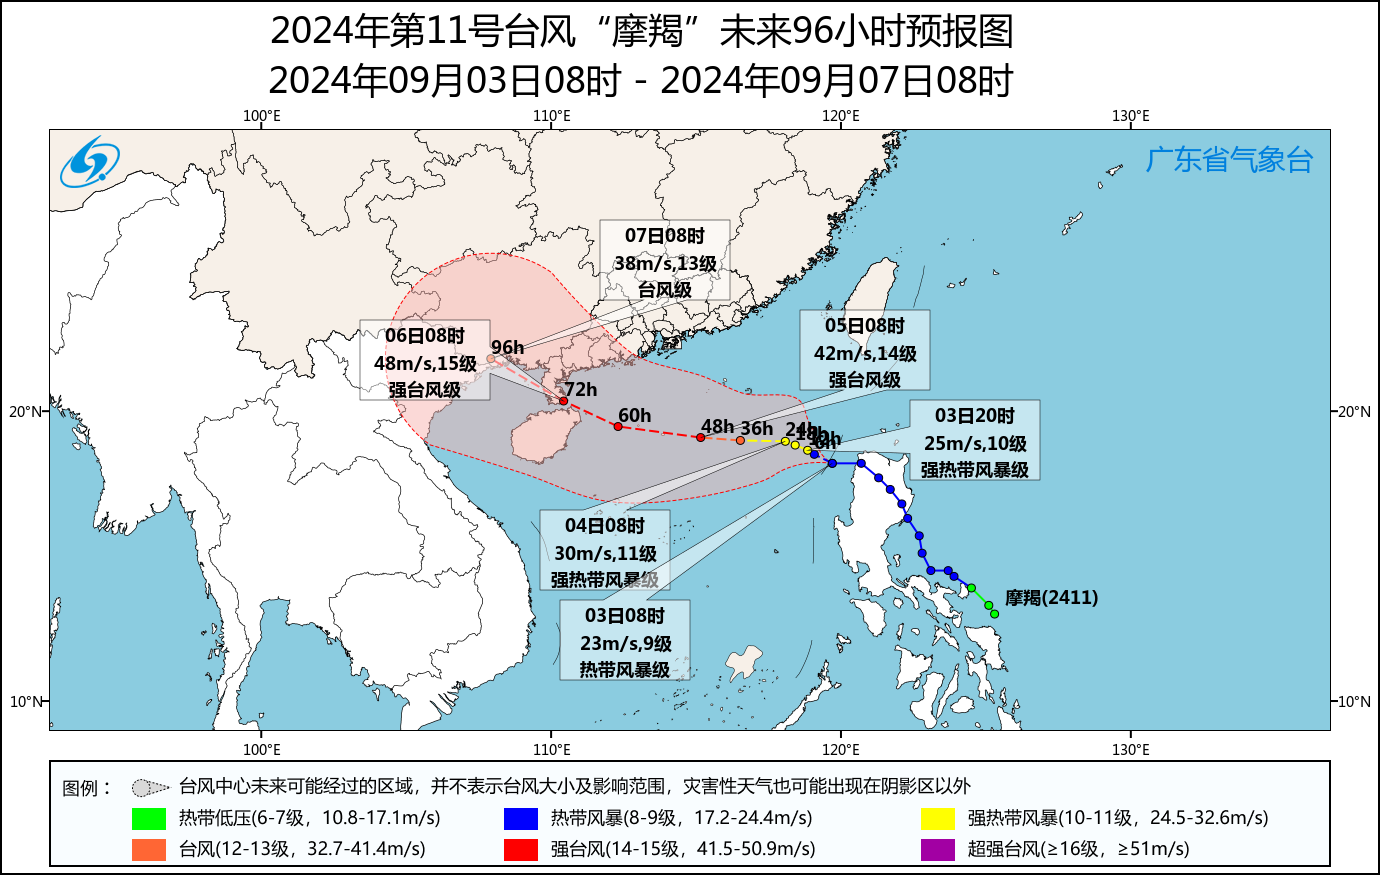

In [12]:
for t in ["2024-09-03 08:00:00", "2024-09-04 02:00:00"]:
    path, used, fb = typhoon.track_image_path(tsid, t)
    print(t, "候选", typhoon.track_candidates(t), "→ 实际用", used, "（回退）" if fb else "")

path, used, _ = typhoon.track_image_path(tsid, "2024-09-03 08:00:00")
display(Image(filename=str(path), width=700))

## T5-3 交给智能体：tsid 必须来自查询结果

检查点：智能体传给路径图工具的 tsid，必须和台风查询返回的一致，不能自己编。

[1] 用户：2024 年 9 月 3 日 08 时的台风路径怎么走？

[2] 模型决定调用工具 get_typhoon_data_by_datetime，参数 {'datetime': '2024-09-03 08:00:00', 'timezone': 'UTC+8'}

[3] 工具 get_typhoon_data_by_datetime 返回：{
 "status": 1,
 "tsid": [
  736
 ],
 "datetime": [
  "2024-09-03 08:00:00"
 ],
 "data": [
  {
   "台风信息": "2024年第11号台风摩羯",
   "路径信息": [
    {
     "预报时间": "2024-09-03 08:00:00",
     "预报时效": "0小时",
     "经度": "119.7",
     "纬度": "18.2",
     "中心风力": "23米/秒",
     "中心最大风力": "28米/秒",
     "中心气压": "987……（共 2642 字，已截断）

[4] 模型决定调用工具 interpret_tc_track_forecast_chart，参数 {'tsid': '736', 'forecast_time': '2024-09-03 08:00:00', 'prompt': '请给出2024年9月3日08时起报的摩羯路径预报：未来24/48/72/96小时的走向、强度变化、登陆或影响区域、以及是否进入南海及广东近海。'}

[5] 工具 interpret_tc_track_forecast_chart 返回：【图片信息】
文件：736_2024090300.png
产品：台风路径预报图（BCGZ）
tsid：736
请求时次（北京时）：2024-09-03 08:00:00
实际时次（北京时）：2024-09-03 08:00:00

【解读内容】
根据广东省气象台2024年9月3日08时发布的台风“摩羯”未来96小时预报图，具体分析如下：

---

### 一、未来 24 / 48 / 72 / 96 小时走向与强度变化

* **起报状态（9月3日08时）：** 
  * 位置：位于吕宋岛西北部近海。
  * 强度：**热带风

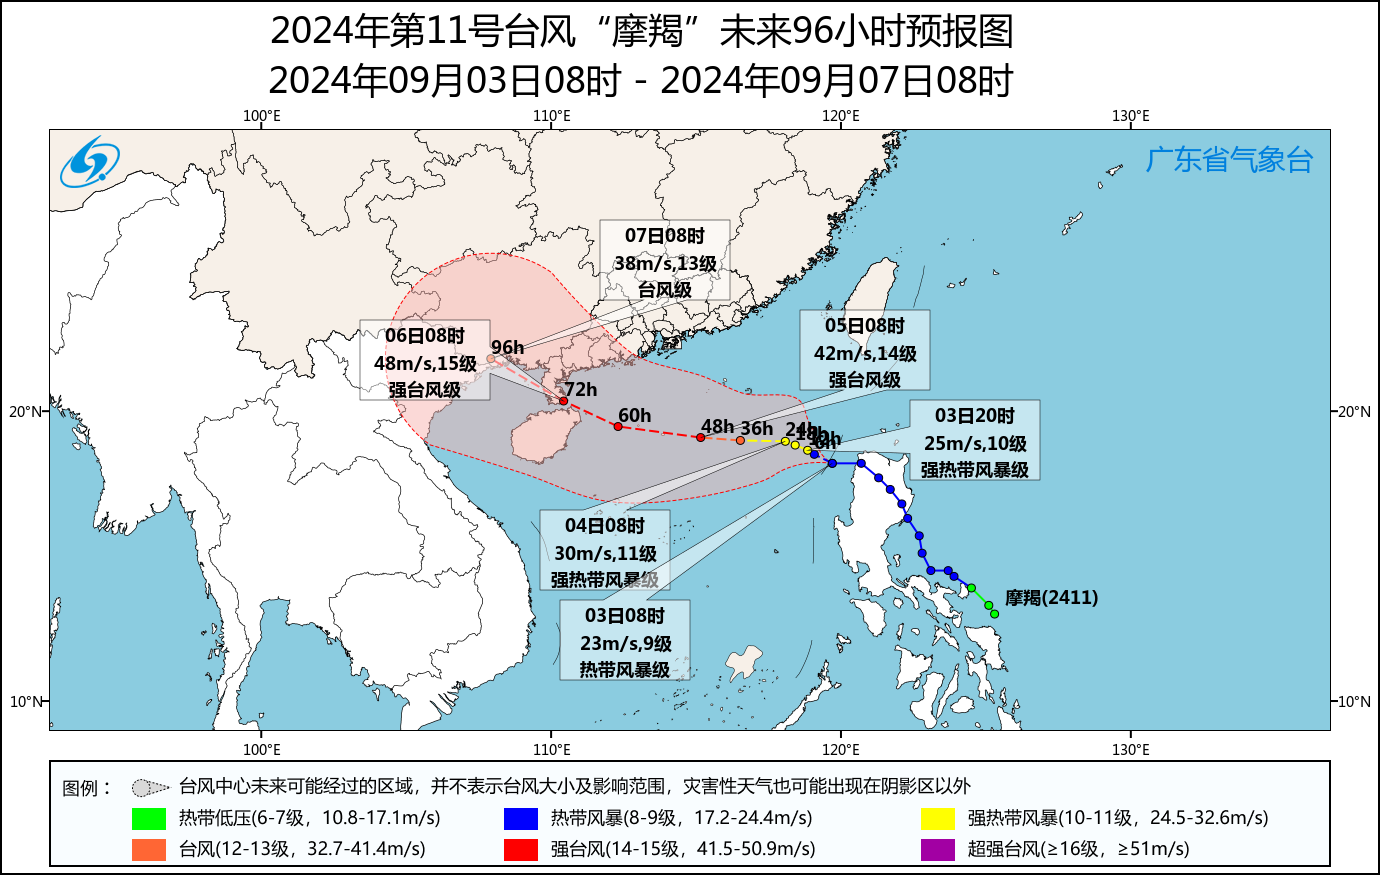

In [13]:
SYSTEM = """你是广东省气象台的台风值班助手。用户说的时间都是北京时。
取路径图前，必须先调用 get_typhoon_data_by_datetime 拿到 tsid。
返回多个台风时，每个台风都要给出结论。"""

model = llm.main_llm()
agent = create_agent(model=model, system_prompt=SYSTEM,
                     tools=[get_typhoon_data_by_datetime, interpret_tc_track_forecast_chart])
res = agent.invoke({"messages": [{"role": "user", "content": "2024 年 9 月 3 日 08 时的台风路径怎么走？"}]})
show(res, max_tool_chars=300)

# 路径图工具返回的是文字解读；根据实际调用参数找到同一张图并展示。
for call in tool_calls(res):
    if call["name"] != "interpret_tc_track_forecast_chart":
        continue
    args = call["args"]
    path, used, fallback = typhoon.track_image_path(str(args["tsid"]), args["forecast_time"])
    if path is None:
        print(f"tsid={args['tsid']}：未找到路径图。")
        continue
    print(f"tsid={args['tsid']}，路径图实际时次（北京时）：{used}"
          + ("（已回退至相邻时次）" if fallback else ""))
    display(Image(filename=str(path), width=700))


In [6]:
calls = tool_calls(res)
queried = [c for c in calls if c["name"] == "get_typhoon_data_by_datetime"]
track = [c for c in calls if c["name"] == "interpret_tc_track_forecast_chart"]
print("先查台风再取路径图：", bool(queried) and calls.index(queried[0]) < calls.index(track[0]))
print("tsid 来自查询结果：", all(c["args"]["tsid"] == tsid for c in track))

先查台风再取路径图： True
tsid 来自查询结果： True
